In [ ]:
import os
from kaggle_secrets import UserSecretsClient
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [4]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
# %% [1] Install (restart kernel after this cell)
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "datasets<4", "transformers>=4.44", "peft>=0.12",
                "accelerate", "jiwer", "soundfile", "librosa"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'datasets<4', 'transformers>=4.44', 'peft>=0.12', 'accelerate', 'jiwer', 'soundfile', 'librosa'], returncode=0)

DatasetDict({
    train: Dataset({
        features: ['input_features', 'labels', 'text'],
        num_rows: 2115
    })
    validation: Dataset({
        features: ['input_features', 'labels', 'text'],
        num_rows: 239
    })
    test: Dataset({
        features: ['input_features', 'labels', 'text'],
        num_rows: 417
    })
})


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

{'WER': 78.07276302851524, 'CER': 44.33297339746736, 'trainable_params': 0, 'total_params': 241734912, 'trainable_pct': 0.0}


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

trainable params: 7,077,888 || all params: 248,812,800 || trainable%: 2.8447


Step,Training Loss,Validation Loss,Wer,Cer
100,0.535504,0.355987,111.851637,107.466404
200,0.318941,0.338167,117.791944,114.417285
300,0.101213,0.388754,131.353231,126.957831
400,0.045838,0.418522,131.556071,119.688369
500,0.012149,0.477886,117.676036,112.667980
536,0.010755,0.479728,110.924370,106.134152


[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=400) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

                      WER    CER  trainable_params  total_params  \
zero-shot           78.07  44.33               0.0   241734912.0   
lora-whisper-small  26.47   9.52         7077888.0   248812800.0   

                    trainable_pct  
zero-shot                    0.00  
lora-whisper-small           2.84  

=== Directed articulatory contrasts (partner_confusion_% is the key metric) ===
                      zero-shot                                            lora-whisper-small                                           
                          n_ref partner_confusion_% other_sub_% deletion_%              n_ref partner_confusion_% other_sub_% deletion_%
contrast                                                                                                                                
unaspirated→aspirated      9039                 1.4        16.7        3.3               9039                 0.7         4.1        1.7
aspirated→unaspirated      1314                31.3       

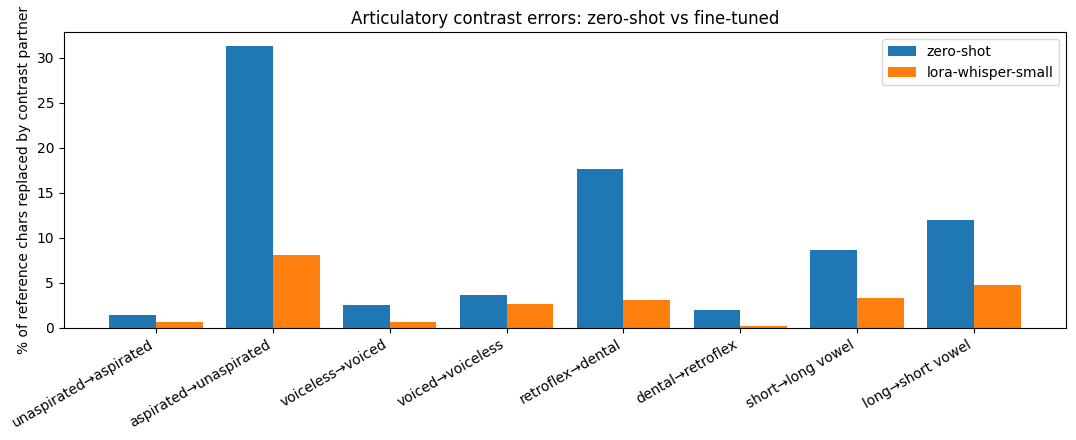

In [5]:
"""
Whisper-small LoRA fine-tuning on Hindi + articulatory error analysis (Kaggle T4).

Pipeline
  1. Load FLEURS hi_in (~10 h train), cache log-mel features to disk
  2. Zero-shot Whisper baseline on the test set
  3. Fine-tune (MODE="lora" for Whisper-small, or MODE="full" with Whisper-base)
  4. Report WER / CER / trainable-parameter %
  5. Character-level alignment of reference vs hypothesis, then error rates per
     articulatory class (aspiration, voicing, retroflex vs dental, vowel length)

Usage on Kaggle
  - Settings: Accelerator = GPU T4 x2, Internet = On
  - Run cell 1, RESTART the kernel, then run the rest
  - To run two configs in parallel, open two notebooks and set GPU=0 / GPU=1
  - To resume after a session cut: save /kaggle/working/<run>/ as a Kaggle Dataset,
    copy it back, and set RESUME = True
"""

# %% [2] Config + imports
import os
os.environ["CUDA_VISIBLE_DEVICES"] = os.environ.get("GPU", "0")  # one GPU avoids DataParallel quirks

import json, unicodedata
from collections import Counter
from dataclasses import dataclass
import numpy as np, pandas as pd, torch, jiwer
import matplotlib.pyplot as plt
from datasets import load_dataset, load_from_disk, DatasetDict, Audio
from transformers import (WhisperProcessor, WhisperForConditionalGeneration,
                          Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)

SEED = 42
MODE = "lora"                        # "lora" (Whisper-small) or "full" (use Whisper-base)
MODEL_ID = "openai/whisper-small"    # for MODE="full" try "openai/whisper-base"
DATASET, CONFIG, TEXT_COL = "google/fleurs", "hi_in", "raw_transcription"
EPOCHS, BS, ACCUM = 8, 16, 2
LR = 1e-3 if MODE == "lora" else 1e-5
RESUME = False

WORK = "/kaggle/working"
RUN = f"{MODEL_ID.split('/')[-1]}-{MODE}"
OUT = f"{WORK}/{RUN}"
CACHE = f"{WORK}/cache_fleurs_hi_80mel"   # same features for whisper-base and small
os.makedirs(OUT, exist_ok=True)
set_seed(SEED)

# %% [3] Data: load, resample, extract features, cache
processor = WhisperProcessor.from_pretrained(MODEL_ID, language="hindi", task="transcribe")
fe, tok = processor.feature_extractor, processor.tokenizer

def load_splits():
    # NOTE: swap this function (and TEXT_COL) if you use another dataset,
    # e.g. a Kathbath / IndicVoices subset. Everything below only needs
    # an "audio" column and a text column.
    d = DatasetDict()
    for s in ["train", "validation", "test"]:
        d[s] = load_dataset(DATASET, CONFIG, split=s, trust_remote_code=True)
    return d

if os.path.exists(CACHE):
    ds = load_from_disk(CACHE)
else:
    raw = load_splits().cast_column("audio", Audio(sampling_rate=16000))
    raw = raw.filter(lambda n: n / 16000 <= 30, input_columns="num_samples")  # Whisper window = 30 s

    def prepare(b):
        return {
            "input_features": fe(b["audio"]["array"], sampling_rate=16000).input_features[0],
            "labels": tok(b[TEXT_COL]).input_ids,
            "text": b[TEXT_COL],
        }

    ds = raw.map(prepare, remove_columns=raw["train"].column_names, writer_batch_size=100)
    ds = ds.filter(lambda l: len(l) <= 448, input_columns="labels")  # decoder max length
    ds.save_to_disk(CACHE)

print(ds)

# %% [4] Text normalisation + metrics
def normalize_hi(t: str) -> str:
    """NFC, drop punctuation/symbols (incl. danda), collapse whitespace.
    Done by Unicode category because Python's \\w drops Devanagari matras."""
    t = unicodedata.normalize("NFC", t)
    t = "".join(c for c in t if not unicodedata.category(c).startswith(("P", "S")))
    return " ".join(t.split())

def score(refs, hyps):
    r = [normalize_hi(x) for x in refs]
    h = [normalize_hi(x) for x in hyps]
    return {"WER": 100 * jiwer.wer(r, h), "CER": 100 * jiwer.cer(r, h)}

def compute_metrics(pred):
    lab = pred.label_ids
    lab[lab == -100] = tok.pad_token_id
    h = tok.batch_decode(pred.predictions, skip_special_tokens=True)
    r = tok.batch_decode(lab, skip_special_tokens=True)
    s = score(r, h)
    return {"wer": s["WER"], "cer": s["CER"]}

@torch.no_grad()
def transcribe(model, dset, bs=16, max_new_tokens=400):
    model.eval().cuda()
    #dset = dset.with_format("numpy")
    hyps = []
    for i in range(0, len(dset), bs):
        feats = torch.from_numpy(np.array(dset[i:i + bs]["input_features"], dtype=np.float32)).cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            ids = model.generate(input_features=feats, language="hindi", task="transcribe",
                                 max_new_tokens=max_new_tokens, num_beams=1)
        hyps += tok.batch_decode(ids, skip_special_tokens=True)
    return hyps

def n_params(m):
    total = sum(p.numel() for p in m.parameters())
    train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return train, total

def build_model():
    m = WhisperForConditionalGeneration.from_pretrained(MODEL_ID)
    m.config.forced_decoder_ids = None
    m.config.suppress_tokens = []
    m.generation_config.forced_decoder_ids = None
    return m

refs = ds["test"]["text"]
results, hyps_by_model = {}, {}

# %% [5] Zero-shot baseline
zs = build_model()
hyps_by_model["zero-shot"] = transcribe(zs, ds["test"])
_, total = n_params(zs)
results["zero-shot"] = {**score(refs, hyps_by_model["zero-shot"]),
                        "trainable_params": 0, "total_params": total, "trainable_pct": 0.0}
print(results["zero-shot"])
del zs; torch.cuda.empty_cache()

# %% [6] Fine-tune
@dataclass
class Collator:
    processor: WhisperProcessor
    decoder_start_token_id: int

    def __call__(self, feats):
        batch = self.processor.feature_extractor.pad(
            [{"input_features": f["input_features"]} for f in feats], return_tensors="pt")
        lab = self.processor.tokenizer.pad(
            [{"input_ids": f["labels"]} for f in feats], return_tensors="pt")
        labels = lab["input_ids"].masked_fill(lab.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

model = build_model()
model.config.use_cache = False

if MODE == "lora":
    from peft import LoraConfig, get_peft_model

    def _require_grad(module, inputs, output):      # needed for gradient checkpointing + frozen encoder input
        output.requires_grad_(True)

    model.model.encoder.conv1.register_forward_hook(_require_grad)
    model = get_peft_model(model, LoraConfig(
        r=32, lora_alpha=64, lora_dropout=0.05, bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "out_proj"]))
    model.print_trainable_parameters()

trainable, total = n_params(model)

args = Seq2SeqTrainingArguments(
    output_dir=OUT,
    per_device_train_batch_size=BS, gradient_accumulation_steps=ACCUM,
    per_device_eval_batch_size=16,
    learning_rate=LR, warmup_steps=50, num_train_epochs=EPOCHS,
    fp16=True,                                   # T4: fp16 yes, bf16 no
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    eval_strategy="steps", eval_steps=100, save_steps=100, logging_steps=25,
    save_total_limit=2, load_best_model_at_end=True,
    metric_for_best_model="wer", greater_is_better=False,
    predict_with_generate=True, generation_max_length=300,
    remove_unused_columns=False, label_names=["labels"],
    report_to="none", seed=SEED, dataloader_num_workers=2,
)

val_small = ds["validation"].select(range(min(150, len(ds["validation"]))))  # fast periodic eval
trainer = Seq2SeqTrainer(
    model=model, args=args,
    train_dataset=ds["train"], eval_dataset=val_small,
    data_collator=Collator(processor, model.config.decoder_start_token_id),
    compute_metrics=compute_metrics,
    processing_class=processor.feature_extractor,
)
trainer.train(resume_from_checkpoint=True if RESUME else None)

trainer.model.save_pretrained(f"{OUT}/final")    # adapter only for LoRA
processor.save_pretrained(f"{OUT}/final")

# %% [7] Evaluate fine-tuned model
final = trainer.model.merge_and_unload() if MODE == "lora" else trainer.model
final.config.use_cache = True
final.generation_config.use_cache = True
name = f"{MODE}-{MODEL_ID.split('/')[-1]}"
hyps_by_model[name] = transcribe(final, ds["test"])
results[name] = {**score(refs, hyps_by_model[name]),
                 "trainable_params": trainable, "total_params": total,
                 "trainable_pct": 100 * trainable / total}

summary = pd.DataFrame(results).T
print(summary.round(2))
summary.to_csv(f"{OUT}/summary.csv")
json.dump(hyps_by_model, open(f"{OUT}/test_hypotheses.json", "w"), ensure_ascii=False, indent=1)

# %% [8] Articulatory taxonomy for Devanagari (grapheme-level proxy)
# Devanagari is largely phonemic, so characters are a reasonable proxy for phones.
STOPS = {"velar": "कखगघ", "palatal": "चछजझ", "retroflex": "टठडढ",
         "dental": "तथदध", "labial": "पफबभ"}      # order: voiceless, voiceless-asp, voiced, voiced-asp

DIRECTED = {k: {} for k in [
    "unaspirated→aspirated", "aspirated→unaspirated",
    "voiceless→voiced", "voiced→voiceless",
    "retroflex→dental", "dental→retroflex",
    "short→long vowel", "long→short vowel"]}

for k, kh, g, gh in STOPS.values():
    for a, b in [(k, kh), (g, gh)]:
        DIRECTED["unaspirated→aspirated"][a] = b
        DIRECTED["aspirated→unaspirated"][b] = a
    for a, b in [(k, g), (kh, gh)]:
        DIRECTED["voiceless→voiced"][a] = b
        DIRECTED["voiced→voiceless"][b] = a
for r, d in list(zip(STOPS["retroflex"], STOPS["dental"])) + [("ण", "न")]:
    DIRECTED["retroflex→dental"][r] = d
    DIRECTED["dental→retroflex"][d] = r
for s, l in [("इ", "ई"), ("उ", "ऊ"), ("ि", "ी"), ("ु", "ू")]:
    DIRECTED["short→long vowel"][s] = l
    DIRECTED["long→short vowel"][l] = s

CLASSES = {
    "aspirated stops": "खघछझठढथधफभ",
    "unaspirated stops": "कगचजटडतदपब",
    "voiceless stops": "कखचछटठतथपफ",
    "voiced stops": "गघजझडढदधबभ",
    "retroflex (ट ठ ड ढ ण)": "टठडढण",
    "dental (त थ द ध न)": "तथदधन",
    "velar stops": "कखगघ", "palatal affricates": "चछजझ", "labial stops": "पफबभ",
    "nasals": "ङञणनम", "fricatives": "शषसह", "semivowels/liquids": "यरलव",
    "short vowels": "अइउऋिुृ", "long vowels": "आईऊएऐओऔाीूेैोौ",
    "nasalisation/nukta/virama": "ंँः़्",
}
CLASSES = {k: set(v) for k, v in CLASSES.items()}

# %% [9] Character alignment + error analysis
def align_chars(ref: str, hyp: str):
    """Levenshtein alignment -> list of (op, ref_char, hyp_char); op in C/S/D/I."""
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), dtype=np.int32)
    D[:, 0] = np.arange(n + 1); D[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i-1, j] + 1, D[i, j-1] + 1,
                          D[i-1, j-1] + (ref[i-1] != hyp[j-1]))
    ops, i, j = [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i-1, j-1] + (ref[i-1] != hyp[j-1]):
            ops.append(("C" if ref[i-1] == hyp[j-1] else "S", ref[i-1], hyp[j-1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i-1, j] + 1:
            ops.append(("D", ref[i-1], None)); i -= 1
        else:
            ops.append(("I", None, hyp[j-1])); j -= 1
    return ops[::-1]

def analyze(refs, hyps):
    tot, hit, oth, dele = Counter(), Counter(), Counter(), Counter()
    ctot, cerr = Counter(), Counter()
    conf = Counter()
    for r, h in zip(refs, hyps):
        r, h = normalize_hi(r).replace(" ", ""), normalize_hi(h).replace(" ", "")
        for op, rc, hc in align_chars(r, h):
            if op == "I":
                continue
            for name, mp in DIRECTED.items():
                if rc in mp:
                    tot[name] += 1
                    if op == "S":
                        (hit if hc == mp[rc] else oth)[name] += 1
                    elif op == "D":
                        dele[name] += 1
            for name, chars in CLASSES.items():
                if rc in chars:
                    ctot[name] += 1
                    cerr[name] += (op != "C")
            if op == "S":
                conf[(rc, hc)] += 1

    contrast = pd.DataFrame([{
        "contrast": k, "n_ref": tot[k],
        "partner_confusion_%": 100 * hit[k] / max(tot[k], 1),
        "other_sub_%": 100 * oth[k] / max(tot[k], 1),
        "deletion_%": 100 * dele[k] / max(tot[k], 1)} for k in DIRECTED])
    classes = pd.DataFrame([{
        "class": k, "n_ref": ctot[k],
        "error_%": 100 * cerr[k] / max(ctot[k], 1)} for k in CLASSES])
    return contrast, classes, conf

analyses = {m: analyze(refs, h) for m, h in hyps_by_model.items()}

# %% [10] Tables, top confusions, plots
contrast_tbl = pd.concat({m: a[0].set_index("contrast") for m, a in analyses.items()}, axis=1)
class_tbl = pd.concat({m: a[1].set_index("class") for m, a in analyses.items()}, axis=1)
contrast_tbl.round(2).to_csv(f"{OUT}/contrast_errors.csv")
class_tbl.round(2).to_csv(f"{OUT}/class_errors.csv")

pd.set_option("display.width", 200)
print("\n=== Directed articulatory contrasts (partner_confusion_% is the key metric) ===")
print(contrast_tbl.round(1))
print("\n=== Per-class character error rate ===")
print(class_tbl.round(1))

for m, (_, _, conf) in analyses.items():
    print(f"\nTop 15 character confusions, {m}:")
    for (r_, h_), c in conf.most_common(15):
        print(f"  {r_} -> {h_} : {c}")

models = list(analyses)
x = np.arange(len(DIRECTED)); w = 0.8 / len(models)
plt.figure(figsize=(11, 4.5))
for i, m in enumerate(models):
    vals = analyses[m][0]["partner_confusion_%"].values
    plt.bar(x + i * w, vals, w, label=m)
plt.xticks(x + w * (len(models) - 1) / 2, list(DIRECTED), rotation=30, ha="right")
plt.ylabel("% of reference chars replaced by contrast partner")
plt.title("Articulatory contrast errors: zero-shot vs fine-tuned")
plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT}/contrast_errors.png", dpi=200)
plt.show()